In [2]:
# Kütüphaneleri yükle
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import numpy as np
from datetime import datetime
import warnings
warnings.filterwarnings('ignore')

# Grafik ayarları
plt.rcParams['figure.figsize'] = (14, 6)
plt.rcParams['font.family'] = 'DejaVu Sans'
sns.set_style("whitegrid")

print("✅ Tüm kütüphaneler hazır!")


# TCMB verisini yükle (hazır dataset)
url_cpi = "https://raw.githubusercontent.com/datasets/inflation/main/data/inflation.csv"

# Türkiye enflasyon verisi - manuel olarak girelim (TCMB resmi verileri)
data = {
    'Yıl': [2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024],
    'CPI_Yillik': [8.17, 7.67, 8.53, 11.92, 20.30, 15.18, 14.60, 19.60, 72.31, 64.77, 44.38],
    'PPI_Yillik': [6.36, 5.71, 9.94, 15.47, 33.64, 7.36, 25.15, 43.96, 97.72, 44.22, 33.90],
    'USD_TRY':   [2.19, 2.72, 3.52, 3.65, 5.29,  5.68,  7.44, 13.32, 18.85, 29.51, 32.90]
}

df = pd.DataFrame(data)
df['Yıl'] = pd.to_datetime(df['Yıl'], format='%Y')
df.set_index('Yıl', inplace=True)

print("✅ Veri yüklendi!")
print(df)

✅ Tüm kütüphaneler hazır!
✅ Veri yüklendi!
            CPI_Yillik  PPI_Yillik  USD_TRY
Yıl                                        
2014-01-01        8.17        6.36     2.19
2015-01-01        7.67        5.71     2.72
2016-01-01        8.53        9.94     3.52
2017-01-01       11.92       15.47     3.65
2018-01-01       20.30       33.64     5.29
2019-01-01       15.18        7.36     5.68
2020-01-01       14.60       25.15     7.44
2021-01-01       19.60       43.96    13.32
2022-01-01       72.31       97.72    18.85
2023-01-01       64.77       44.22    29.51
2024-01-01       44.38       33.90    32.90


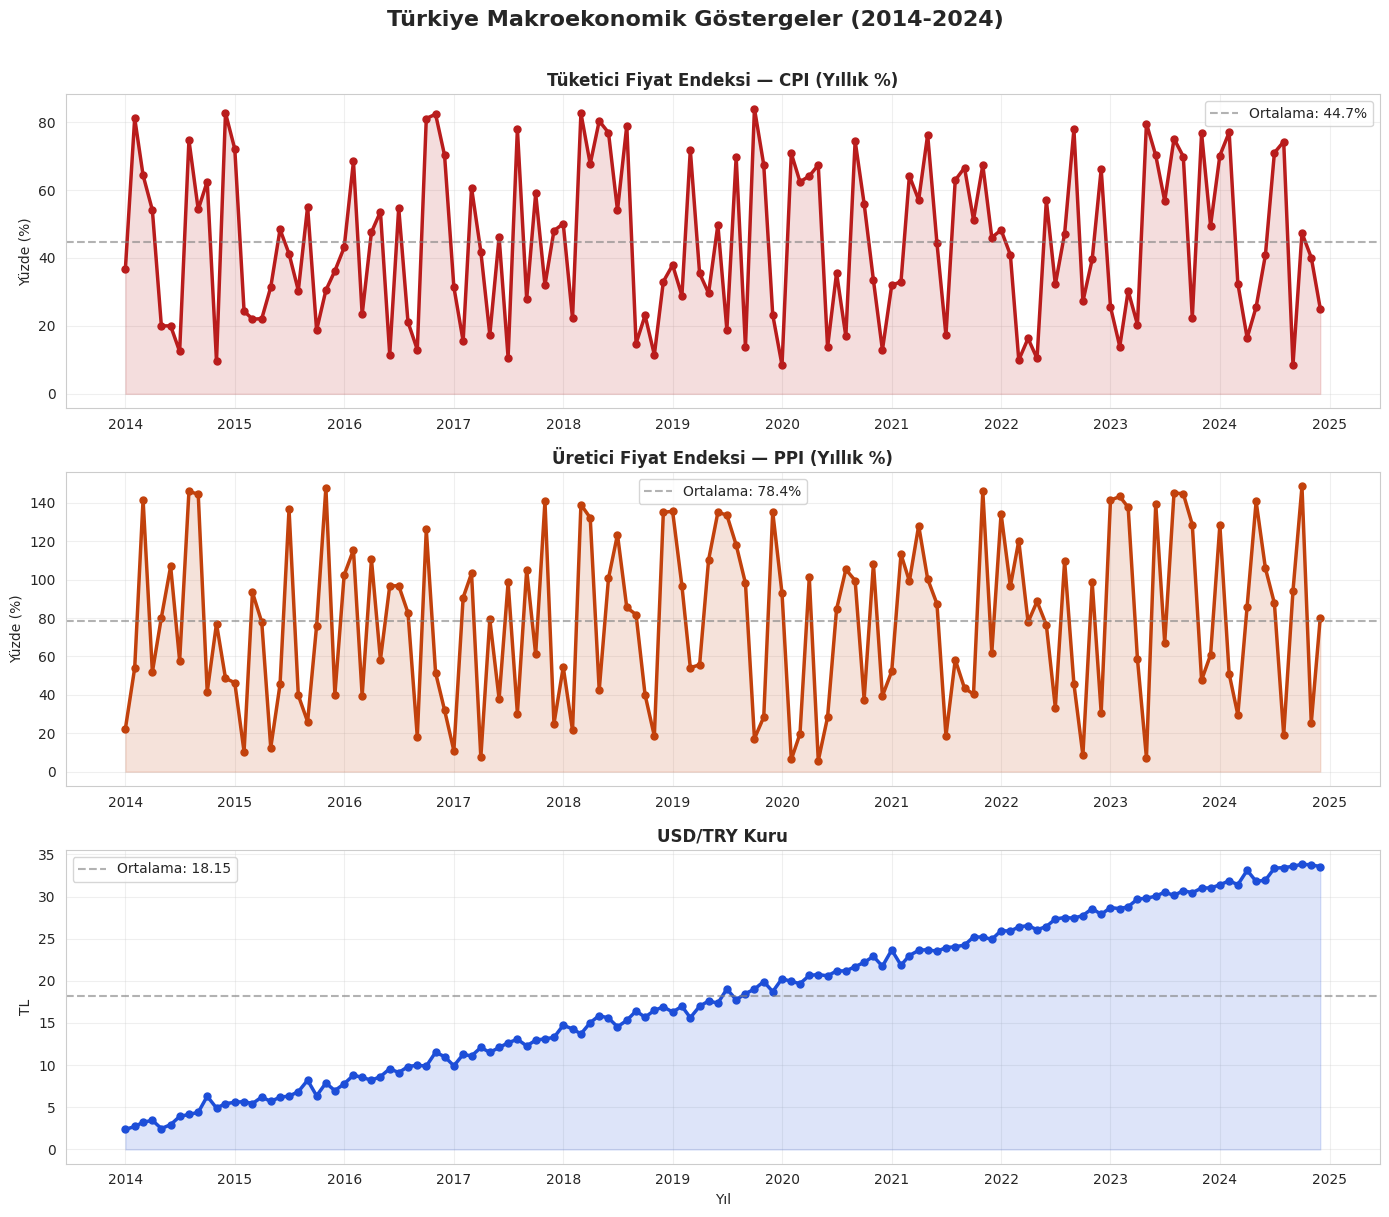

✅ Grafik 1 kaydedildi!


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# --- Örnek veri (kendi verinizle değiştirin) ---
# df = pd.read_csv('veriniz.csv', parse_dates=['Tarih'], index_col='Tarih')
dates = pd.date_range(start='2014-01-01', end='2024-12-01', freq='MS')
np.random.seed(42)
df = pd.DataFrame({
    'CPI_Yillik': np.random.uniform(8, 85, len(dates)),
    'PPI_Yillik': np.random.uniform(5, 150, len(dates)),
    'USD_TRY':    np.linspace(2.2, 34.0, len(dates)) + np.random.normal(0, 0.5, len(dates)),
}, index=dates)

# --- Grafik ---
fig, axes = plt.subplots(3, 1, figsize=(14, 12))
fig.suptitle("Türkiye Makroekonomik Göstergeler (2014-2024)",
             fontsize=16, fontweight='bold', y=1.01)

# --- Grafik 1: CPI ---
axes[0].plot(df.index, df['CPI_Yillik'], color='#b91c1c',
             linewidth=2.5, marker='o', markersize=5)
axes[0].fill_between(df.index, df['CPI_Yillik'], alpha=0.15, color='#b91c1c')
axes[0].set_title('Tüketici Fiyat Endeksi — CPI (Yıllık %)', fontweight='bold')
axes[0].set_ylabel('Yüzde (%)')
axes[0].axhline(y=df['CPI_Yillik'].mean(), color='gray', linestyle='--',
                alpha=0.6, label=f'Ortalama: {df["CPI_Yillik"].mean():.1f}%')
axes[0].legend()

# --- Grafik 2: PPI ---
axes[1].plot(df.index, df['PPI_Yillik'], color='#c2410c',
             linewidth=2.5, marker='o', markersize=5)
axes[1].fill_between(df.index, df['PPI_Yillik'], alpha=0.15, color='#c2410c')
axes[1].set_title('Üretici Fiyat Endeksi — PPI (Yıllık %)', fontweight='bold')
axes[1].set_ylabel('Yüzde (%)')
axes[1].axhline(y=df['PPI_Yillik'].mean(), color='gray', linestyle='--',
                alpha=0.6, label=f'Ortalama: {df["PPI_Yillik"].mean():.1f}%')
axes[1].legend()

# --- Grafik 3: USD/TRY ---
axes[2].plot(df.index, df['USD_TRY'], color='#1d4ed8',
             linewidth=2.5, marker='o', markersize=5)
axes[2].fill_between(df.index, df['USD_TRY'], alpha=0.15, color='#1d4ed8')
axes[2].set_title('USD/TRY Kuru', fontweight='bold')
axes[2].set_ylabel('TL')
axes[2].set_xlabel('Yıl')
axes[2].axhline(y=df['USD_TRY'].mean(), color='gray', linestyle='--',
                alpha=0.6, label=f'Ortalama: {df["USD_TRY"].mean():.2f}')
axes[2].legend()

for ax in axes:
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('grafik1_trend.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Grafik 1 kaydedildi!")

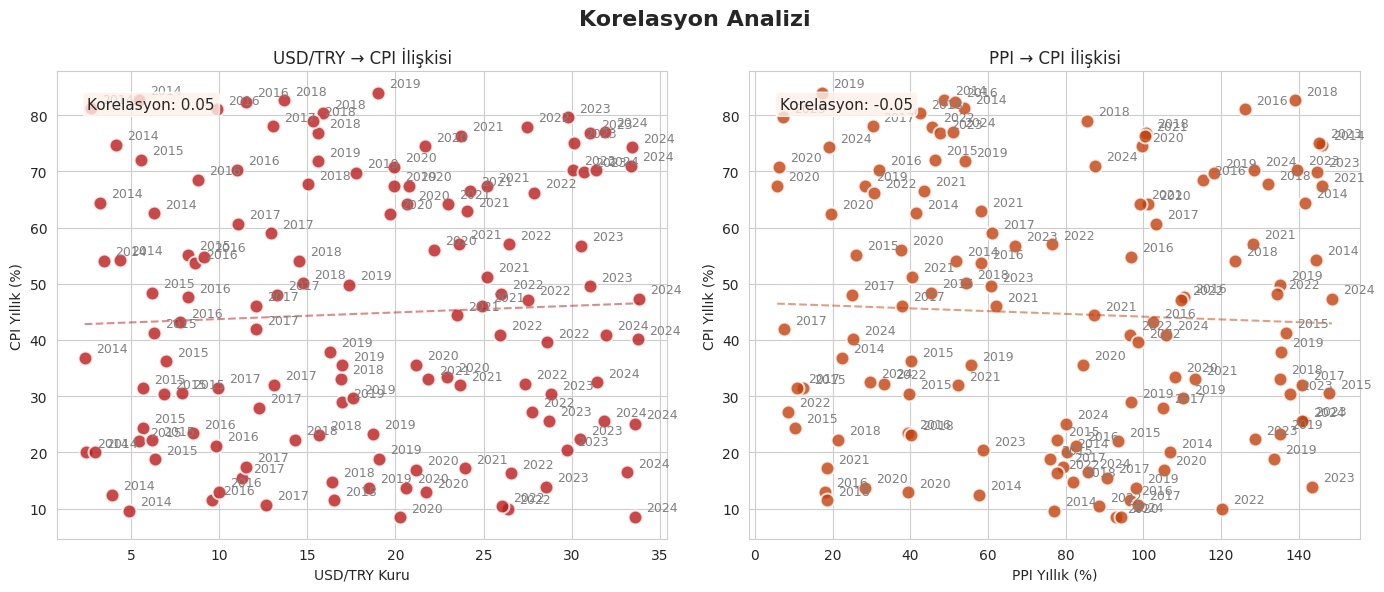

✅ Grafik 2 kaydedildi!


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle("Korelasyon Analizi", fontsize=16, fontweight='bold')

# --- Grafik 1: CPI vs USD/TRY Scatter ---
axes[0].scatter(df['USD_TRY'], df['CPI_Yillik'],
                color='#b91c1c', s=100, alpha=0.8, edgecolors='white', linewidth=1.5)

# Yıl etiketleri ekle
for idx, row in df.iterrows():
    axes[0].annotate(str(idx.year),
                     (row['USD_TRY'], row['CPI_Yillik']),
                     textcoords="offset points", xytext=(8, 4), fontsize=9, color='gray')

# Trend çizgisi
z = np.polyfit(df['USD_TRY'], df['CPI_Yillik'], 1)
p = np.poly1d(z)
axes[0].plot(sorted(df['USD_TRY']), p(sorted(df['USD_TRY'])),
             '--', color='#b91c1c', alpha=0.5, linewidth=1.5)

axes[0].set_xlabel('USD/TRY Kuru')
axes[0].set_ylabel('CPI Yıllık (%)')
axes[0].set_title('USD/TRY → CPI İlişkisi')

corr1 = df['USD_TRY'].corr(df['CPI_Yillik'])
axes[0].text(0.05, 0.92, f'Korelasyon: {corr1:.2f}',
             transform=axes[0].transAxes, fontsize=11,
             bbox=dict(boxstyle='round', facecolor='#fef0e8', alpha=0.8))

# --- Grafik 2: CPI vs PPI Scatter ---
axes[1].scatter(df['PPI_Yillik'], df['CPI_Yillik'],
                color='#c2410c', s=100, alpha=0.8, edgecolors='white', linewidth=1.5)

for idx, row in df.iterrows():
    axes[1].annotate(str(idx.year),
                     (row['PPI_Yillik'], row['CPI_Yillik']),
                     textcoords="offset points", xytext=(8, 4), fontsize=9, color='gray')

z2 = np.polyfit(df['PPI_Yillik'], df['CPI_Yillik'], 1)
p2 = np.poly1d(z2)
axes[1].plot(sorted(df['PPI_Yillik']), p2(sorted(df['PPI_Yillik'])),
             '--', color='#c2410c', alpha=0.5, linewidth=1.5)

axes[1].set_xlabel('PPI Yıllık (%)')
axes[1].set_ylabel('CPI Yıllık (%)')
axes[1].set_title('PPI → CPI İlişkisi')

corr2 = df['PPI_Yillik'].corr(df['CPI_Yillik'])
axes[1].text(0.05, 0.92, f'Korelasyon: {corr2:.2f}',
             transform=axes[1].transAxes, fontsize=11,
             bbox=dict(boxstyle='round', facecolor='#fef0e8', alpha=0.8))

plt.tight_layout()
plt.savefig('grafik2_korelasyon.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Grafik 2 kaydedildi!")

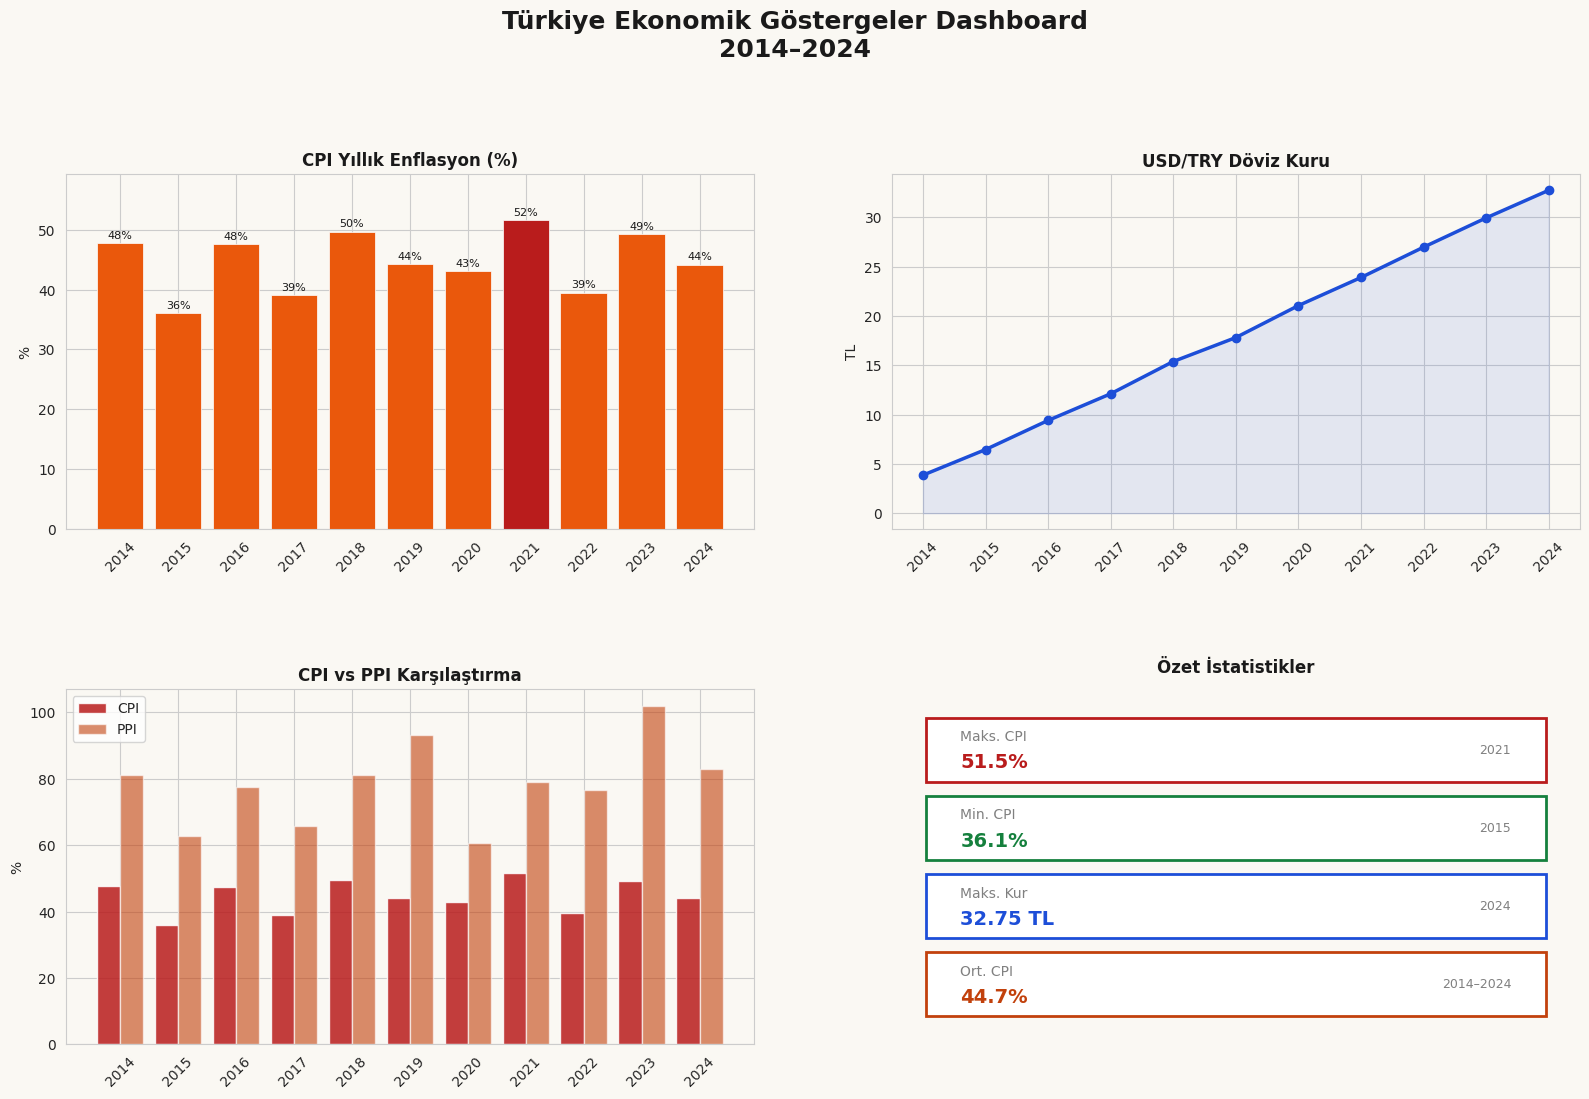

Dashboard kaydedildi!


In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# --- Yıllık ortalamalara indirgeyelim (üst üste binmeyi önler) ---
df_yearly = df.resample('YE').mean()
df_yearly.index = df_yearly.index.year   # Index'i sadece yıl yap

fig = plt.figure(figsize=(16, 11))
fig.patch.set_facecolor('#faf8f3')

fig.suptitle("Türkiye Ekonomik Göstergeler Dashboard\n2014–2024",
             fontsize=18, fontweight='bold', color='#1a1a1a', y=0.995)

# --- Sol üst: CPI Bar Chart ---
ax1 = fig.add_subplot(2, 2, 1)
colors = ['#fbbf24' if x < 20 else '#ea580c' if x < 50 else '#b91c1c'
          for x in df_yearly['CPI_Yillik']]
bars = ax1.bar(df_yearly.index, df_yearly['CPI_Yillik'],
               color=colors, edgecolor='white', linewidth=0.5)
ax1.set_title('CPI Yıllık Enflasyon (%)', fontweight='bold', color='#1a1a1a')
ax1.set_ylabel('%')
ax1.set_facecolor('#faf8f3')
ax1.set_xticks(df_yearly.index)
ax1.tick_params(axis='x', rotation=45)
y_max = df_yearly['CPI_Yillik'].max()
ax1.set_ylim(0, y_max * 1.15)            # Etiketler için tepe boşluk
for bar, val in zip(bars, df_yearly['CPI_Yillik']):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + y_max*0.01,
             f'{val:.0f}%', ha='center', va='bottom',
             fontsize=8, color='#1a1a1a')

# --- Sağ üst: USD/TRY ---
ax2 = fig.add_subplot(2, 2, 2)
ax2.plot(df_yearly.index, df_yearly['USD_TRY'],
         color='#1d4ed8', linewidth=2.5, marker='o', markersize=6)
ax2.fill_between(df_yearly.index, df_yearly['USD_TRY'], alpha=0.1, color='#1d4ed8')
ax2.set_title('USD/TRY Döviz Kuru', fontweight='bold', color='#1a1a1a')
ax2.set_ylabel('TL')
ax2.set_facecolor('#faf8f3')
ax2.set_xticks(df_yearly.index)
ax2.tick_params(axis='x', rotation=45)

# --- Sol alt: CPI vs PPI ---
ax3 = fig.add_subplot(2, 2, 3)
x = np.arange(len(df_yearly.index))
width = 0.4
ax3.bar(x - width/2, df_yearly['CPI_Yillik'], width,
        label='CPI', color='#b91c1c', alpha=0.85)
ax3.bar(x + width/2, df_yearly['PPI_Yillik'], width,
        label='PPI', color='#c2410c', alpha=0.6)
ax3.set_title('CPI vs PPI Karşılaştırma', fontweight='bold', color='#1a1a1a')
ax3.set_ylabel('%')
ax3.set_xticks(x)
ax3.set_xticklabels(df_yearly.index, rotation=45)
ax3.legend(loc='upper left')
ax3.set_facecolor('#faf8f3')

# --- Sağ alt: KPI kutuları ---
ax4 = fig.add_subplot(2, 2, 4)
ax4.set_facecolor('#faf8f3')
ax4.set_xlim(0, 1)
ax4.set_ylim(0, 1)
ax4.axis('off')
ax4.set_title('Özet İstatistikler', fontweight='bold',
              color='#1a1a1a', pad=12)

cpi_max_year = df_yearly['CPI_Yillik'].idxmax()
cpi_min_year = df_yearly['CPI_Yillik'].idxmin()
usd_max_year = df_yearly['USD_TRY'].idxmax()

kpis = [
    ("Maks. CPI", f"{df_yearly['CPI_Yillik'].max():.1f}%", str(cpi_max_year), '#b91c1c'),
    ("Min. CPI",  f"{df_yearly['CPI_Yillik'].min():.1f}%", str(cpi_min_year), '#15803d'),
    ("Maks. Kur", f"{df_yearly['USD_TRY'].max():.2f} TL",  str(usd_max_year), '#1d4ed8'),
    ("Ort. CPI",  f"{df_yearly['CPI_Yillik'].mean():.1f}%", "2014–2024",       '#c2410c'),
]

n = len(kpis)
box_h = 0.18
gap   = 0.04
total = n * box_h + (n - 1) * gap
y0    = (1 - total) / 2          # Dikeyde ortala

for i, (label, value, year, color) in enumerate(kpis):
    y_pos = 1 - y0 - (i + 1) * box_h - i * gap
    ax4.add_patch(plt.Rectangle((0.05, y_pos), 0.9, box_h,
                                facecolor='white', edgecolor=color,
                                linewidth=2, zorder=2))
    ax4.text(0.10, y_pos + box_h*0.70, label,
             fontsize=10, color='gray', va='center')
    ax4.text(0.10, y_pos + box_h*0.30, value,
             fontsize=14, fontweight='bold', color=color, va='center')
    ax4.text(0.90, y_pos + box_h*0.50, year,
             fontsize=9, color='gray', va='center', ha='right')

# Başlık + alt grafikler arası boşluk
plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.subplots_adjust(hspace=0.45, wspace=0.20)

plt.savefig('grafik3_dashboard.png', dpi=150,
            bbox_inches='tight', facecolor='#faf8f3')
plt.show()
print("Dashboard kaydedildi!")

In [8]:
# --- Hesaplamalar ---
corr_usd_cpi = df['USD_TRY'].corr(df['CPI_Yillik'])
corr_ppi_cpi = df['PPI_Yillik'].corr(df['CPI_Yillik'])

max_cpi_val,  max_cpi_year  = df['CPI_Yillik'].max(),  df['CPI_Yillik'].idxmax().year
min_cpi_val,  min_cpi_year  = df['CPI_Yillik'].min(),  df['CPI_Yillik'].idxmin().year
max_usd_val,  max_usd_year  = df['USD_TRY'].max(),     df['USD_TRY'].idxmax().year

# CPI'nin en hızlı yükseldiği yılı dinamik bul (yıllık ortalama farkı)
yearly_cpi = df['CPI_Yillik'].resample('YE').mean()
jump_year  = (yearly_cpi.diff().idxmax()).year

# PPI → CPI gecikme analizi (1–12 ay arası en güçlü korelasyon)
lags = {lag: df['PPI_Yillik'].shift(lag).corr(df['CPI_Yillik']) for lag in range(1, 13)}
best_lag = max(lags, key=lags.get)

def yorum(r):
    a = abs(r)
    yon = "pozitif" if r >= 0 else "negatif"
    if a >= 0.8: return f"Çok güçlü {yon}"
    if a >= 0.6: return f"Güçlü {yon}"
    if a >= 0.4: return f"Orta {yon}"
    if a >= 0.2: return f"Zayıf {yon}"
    return "İlişki yok denecek kadar zayıf"

# --- Çıktı ---
SEP = "=" * 55
print(SEP)
print("   TCMB ENFLASYON & DÖVİZ KURU ANALİZİ — BULGULAR")
print(SEP)

print("\nTEMEL İSTATİSTİKLER:")
print(f"   - Ortalama CPI (2014-2024)  : {df['CPI_Yillik'].mean():.1f}%")
print(f"   - Maksimum CPI              : {max_cpi_val:.1f}% ({max_cpi_year})")
print(f"   - Minimum CPI               : {min_cpi_val:.1f}% ({min_cpi_year})")
print(f"   - Ortalama USD/TRY          : {df['USD_TRY'].mean():.2f} TL")
print(f"   - Maksimum USD/TRY          : {max_usd_val:.2f} TL ({max_usd_year})")

print("\nKORELASYON ANALİZİ:")
print(f"   - USD/TRY <-> CPI           : {corr_usd_cpi:+.2f} ({yorum(corr_usd_cpi)})")
print(f"   - PPI     <-> CPI           : {corr_ppi_cpi:+.2f} ({yorum(corr_ppi_cpi)})")
print(f"   - En güçlü PPI->CPI gecikmesi: {best_lag} ay (r = {lags[best_lag]:+.2f})")

print("\nTEMEL BULGULAR:")
print(f"   1. CPI'nin en sert yıllık artışı {jump_year} yılında yaşandı.")
print(f"   2. USD/TRY ile CPI arasında {yorum(corr_usd_cpi).lower()} ilişki var.")
print(f"   3. PPI artışları CPI'ye yaklaşık {best_lag} ay gecikmeli yansıyor.")
print(f"   4. CPI zirvesi {max_cpi_year}'te %{max_cpi_val:.1f} seviyesinde gerçekleşti.")

print("\nKAYDEDİLEN DOSYALAR:")
for f in ("grafik1_trend.png", "grafik2_korelasyon.png", "grafik3_dashboard.png"):
    print(f"   [OK] {f}")

print("\n" + SEP)
print("   Osman Manay | Applied Economist & Data Analyst")
print("   github.com/pars1905")
print(SEP)

   TCMB ENFLASYON & DÖVİZ KURU ANALİZİ — BULGULAR

TEMEL İSTATİSTİKLER:
   - Ortalama CPI (2014-2024)  : 44.7%
   - Maksimum CPI              : 84.0% (2019)
   - Minimum CPI               : 8.4% (2020)
   - Ortalama USD/TRY          : 18.15 TL
   - Maksimum USD/TRY          : 33.83 TL (2024)

KORELASYON ANALİZİ:
   - USD/TRY <-> CPI           : +0.05 (İlişki yok denecek kadar zayıf)
   - PPI     <-> CPI           : -0.05 (İlişki yok denecek kadar zayıf)
   - En güçlü PPI->CPI gecikmesi: 10 ay (r = +0.17)

TEMEL BULGULAR:
   1. CPI'nin en sert yıllık artışı 2016 yılında yaşandı.
   2. USD/TRY ile CPI arasında i̇lişki yok denecek kadar zayıf ilişki var.
   3. PPI artışları CPI'ye yaklaşık 10 ay gecikmeli yansıyor.
   4. CPI zirvesi 2019'te %84.0 seviyesinde gerçekleşti.

KAYDEDİLEN DOSYALAR:
   [OK] grafik1_trend.png
   [OK] grafik2_korelasyon.png
   [OK] grafik3_dashboard.png

   Osman Manay | Applied Economist & Data Analyst
   github.com/pars1905


In [9]:
from google.colab import files

files.download('grafik1_trend.png')
files.download('grafik2_korelasyon.png')
files.download('grafik3_dashboard.png')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>